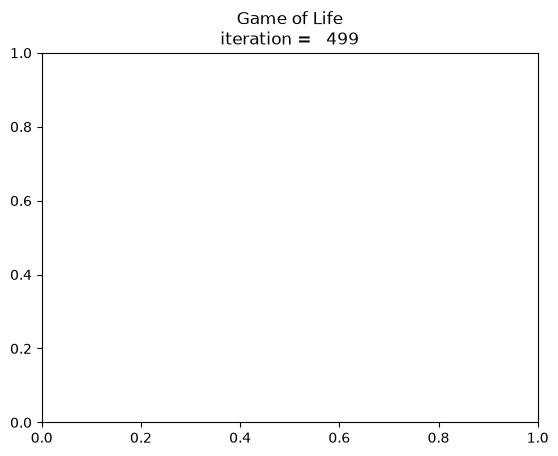

In [3]:
from IPython.display import HTML

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as ani
class life():
    def __init__(self,nx,ny):   
        """
        Basic object of the Game of Life, given an initial pattern it evolves according 
        to the 2,3 | 3 rules.

        Attributes of this object are:
        shape = (nx, ny) : dimensions of the game board along the x and y axes
        cells = ndarray  : 2D numpy array of integers (0 or 1) with dimensions equal to shape
        """
        self.rng = np.random.default_rng()
        self.shape = (nx, ny)
        self.cells = self.rng.integers(0,2, (nx,ny))
    
    def step(self):
        """
        Perform one step of evolution accoring to the laws of 
        Conway's Game of Life: 
        
        A cell stays alive if 2 or 3 neighboring cells are alive
        A dead cell becomes alive if 3 neighboring cells are alive
        
        """
        newlife=np.zeros((self.shape[0],self.shape[1]))
        for i in range(1,self.shape[0]):
            for j in range(1,self.shape[1]):
                neighbors = self.cells[i-1:i+2,j-1:j+2].copy()
                neighbors[1,1]=0
                alive = np.count_nonzero(neighbors)
                if ( alive == 2 ):
                    newlife[i,j]=self.cells[i,j]
                if ( alive == 3 ): 
                    newlife[i,j]=1
        self.cells=newlife

np.random.seed(23456)
nx=100
ny=100
test=life(nx,ny)
test.cells = np.zeros((nx,ny))

# Glider!
# test.cells[10,10]=1
# test.cells[10,11]=1
# test.cells[10,12]=1
# test.cells[9,12]=1
# test.cells[8,11]=1

# heavy weight space ship!
# test.cells[11,5:7]=1
# test.cells[12:15,1:7]=1
# test.cells[12,5]=0
# test.cells[12,7]=1
# test.cells[14,1]=0
# test.cells[14,6]=0

#block-laying engine 1
# test.cells[51,51:56]=1
# test.cells[51,54]=0
# test.cells[52,51]=1
# test.cells[53,54:56]=1
# test.cells[54,52:54]=1
# test.cells[54,55]=1
# test.cells[55,51:56:2]=1

# block-laying engine double path
# test.cells[141,21:29]=1
# test.cells[141,30:35]=1
# test.cells[141,38:41]=1
# test.cells[141,47:54]=1
# test.cells[141,55:60]=1

# R-pentomino. A small seed pattern that can self-sustain for >1000 generations!
test.cells[51,52:54]=1
test.cells[52,51:53]=1
test.cells[53,52]=1

# Glider Gun!
# test.cells[1,25]=1
# test.cells[2,23]=1
# test.cells[2,25]=1
# test.cells[3,13:15]=1
# test.cells[3:6,21:23]=1
# test.cells[4,12]=1
# test.cells[4,16]=1
# test.cells[5:7,1:3]=1
# test.cells[5:8,11]=1
# test.cells[5:8,17]=1
# test.cells[6,15]=1
# test.cells[6,18]=1
# test.cells[6,23]=1
# test.cells[6:8,25]=1
# test.cells[8,12]=1
# test.cells[8,16]=1
# test.cells[9,13:15]=1
# test.cells[3:5,35:37]=1

fig, axes = plt.subplots(1)
a=axes.matshow(test.cells)
axes.get_xaxis().set_visible(False)
axes.get_yaxis().set_visible(False)
plt.title('Game of Life \niteration = {0: 5.0f}'.format(0))

def animate(i):
    test.step()
    a.set_data(test.cells)
    plt.title('Game of Life\niteration = {0: 5.0f}'.format(i))

anim = ani.FuncAnimation(fig, animate, frames=500, interval=1)

plt.close(fig)
HTML(anim.to_jshtml())